 Project3: bar chart, t-test, regression, and a peer industry

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Setup. Libraries and settings</h2>

In [1]:
# ===== Setup =====
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import seaborn as sns                      # a library on top of matplotlib: nicer defaults with less code
from scipy import stats                    # t-test
import statsmodels.formula.api as smf      # regression with a full results table
from statsmodels.iolib.summary2 import summary_col   # puts several regressions side by side
import wrds

conn = wrds.Connection()

# Settings (the same as Project 2). Change them here only.
SIC        = "13"            # my industry (Oil and Gas Extraction)
PEER_SIC   = "63"            # the peer industry for Part 5 (Insurance Carriers), the comparison industry assigned to Oil and Gas
FY_START   = "2021-01-01"    # we keep announcements (rdq) between FY_START and FY_END (Rule 2)
FY_END     = "2024-12-31"
PULL_START = "2019-06-01"    # we pull earlier quarters too, because SUE needs EPS from 4 quarters ago
RET_START  = "2020-12-01"    # first day of daily returns
RET_END    = "2025-01-31"    # last day of daily returns
MIN_PRC    = 5               # Rule 4: drop a company-quarter if last quarter's price is below this
MAX_CHG    = 1               # Rule 5: drop a company-quarter if |SUE| is bigger than this

LABELS = ["Low", "Middle", "High"]

Loading library list...
Done


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 1. Build the table </h2>

**Steps 1–2.** Read the link file (gvkey ↔ permno), keep the companies in my industry, and pull their quarterly EPS, price and announcement date (rdq) from Compustat.

In [2]:
# ===== Step 1. Read the link file =====

#  Read every column as text, so that nothing is changed or guessed at this point.
link_all = pd.read_csv("ccm_link.csv", dtype=str)

# 1b. gvkey must have 6 characters (for example 001690). Excel can drop the leading zeros, so we put them back.
link_all["gvkey"] = link_all["gvkey"].str.zfill(6)

# 1c. permno is a number.
link_all["permno"] = pd.to_numeric(link_all["permno"]).astype(int)

# 1d. The two date columns are text. Turn them into real dates, so that we can compare them with other dates.
# format="mixed" accepts different date formats. errors="coerce" turns a bad value into a missing date.
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")

# 1e. A link with no end date is still valid, so we give it a far-future end date.
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# 1f. Keep only the companies in our industry.
link = link_all[link_all["sic2"] == SIC].reset_index(drop=True)
if len(link) == 0:
    raise ValueError("SIC " + SIC + " is not in ccm_link.csv. Industries in the file: " + str(sorted(link_all["sic2"].unique())))

print("link rows:", len(link), "| companies:", link["gvkey"].nunique())
link.head()

# ===== Step 2. Pull the quarterly data =====

# 2a. The SQL query needs the gvkeys as one text
gv = "'" + "','".join(link["gvkey"].unique()) + "'"

# 2b. Ask WRDS for only the rows and columns we need.
fa = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, epspxq, prccq, rdq
    from comp.fundq
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{FY_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate"])

# 2c. WRDS can return numbers in a special type. Turn them into plain decimal numbers (missing values become NaN).
fa["epspxq"]  = fa["epspxq"].astype("float64")
fa["prccq"] = fa["prccq"].astype("float64")

# 2d. Check what we got.
print("company-quarters pulled from Compustat:", len(fa))
fa.head()

link rows: 196 | companies: 171
company-quarters pulled from Compustat: 3285


,gvkey,datadate,fyearq,fqtr,epspxq,prccq,rdq
0,001661,2019-06-30,2019,2,-0.61,2.90,2019-07-29
1,001678,2019-06-30,2019,2,-0.96,28.97,2019-07-31
2,002052,2019-06-30,2019,3,-0.16,1.13,2019-08-12
3,002270,2019-06-30,2019,2,2.09,8.53,2019-08-01
4,003806,2019-06-30,2019,2,-0.49,2.50,2019-08-01


**Step 3.** Merge 1 adds permno with a valid link date. Merge 2 adds EPS from four quarters ago and last quarter's price, so I can compute SUE. Then Rules 1 to 5.

In [3]:
# ===== Step 3a. Merge 1: add permno from the link file =====
panel = fa.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
print("3a. after the merge (a gvkey with 2 links is now on 2 rows):", len(panel))

# ===== Step 3b. Keep only the link that was valid on the fiscal quarter-end date =====

# True/False for each row: the date is between the start and the end of the link.
valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
panel = panel[valid]

# How many rows share the same gvkey + fyearq + fqtr with another row?
n_dup = panel.duplicated(["gvkey", "fyearq", "fqtr"]).sum()
print("3b. rows that repeat a gvkey + fyearq + fqtr before we drop them:", n_dup)

# If one company-quarter still has two rows, keep one.
panel = panel.drop_duplicates(["gvkey", "fyearq", "fqtr"])

# We do not need the link dates any more.
panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)

# Count (used in the sample construction table in Step 6).
r1, c1 = len(fa), fa["gvkey"].nunique()          # before the link
r2, c2 = len(panel), panel["gvkey"].nunique()    # after the link
print("3b. company-quarters after the link merge:", r2)

# ===== Check: does any key (gvkey + fyearq+fqtr) appear more than once? =====
# duplicated() marks a row True if an earlier row has the same gvkey, fyearq and fqtr. sum() counts the True values.
print("duplicate keys:", panel.duplicated(["gvkey", "fyearq", "fqtr"]).sum(), "(it must be 0)")

# ===== Step 3c. Merge 2: add last year's EPS and price =====


# 1. Create a continuous quarter number
panel["quarter_num"] = (panel["fyearq"] * 4) + panel["fqtr"]

# 2.Sort by company and quarter number so shifting works in chronological order
panel = panel.sort_values(by=["gvkey", "quarter_num"]).reset_index(drop=True)

# 3. Create lag 4 for EPS (same quarter last year) and lag 1 for price (end of previous quarter).
lags = panel.dropna(subset=["quarter_num"])[["gvkey", "quarter_num", "epspxq", "prccq"]]
lag4 = lags[["gvkey", "quarter_num", "epspxq"]].assign(quarter_num=lags["quarter_num"] + 4).rename(columns={"epspxq": "eps_lag4"})
lag1 = lags[["gvkey", "quarter_num", "prccq"]].assign(quarter_num=lags["quarter_num"] + 1).rename(columns={"prccq": "prc_lag1"})
panel = panel.merge(lag4, on=["gvkey", "quarter_num"], how="left")
panel = panel.merge(lag1, on=["gvkey", "quarter_num"], how="left")
r2b, c2b = len(panel), panel["gvkey"].nunique()
print("3c. after Merge 2 (left join, rows must not change):", r2b)

# 4. Compute SUE = (EPS this quarter - EPS four quarters ago) / Price one quarter ago
panel["sue"] = (panel["epspxq"] - panel["eps_lag4"]) / panel["prc_lag1"]

# 5. Check the result
display(panel[["gvkey", "fyearq", "fqtr", "epspxq", "eps_lag4", "prc_lag1", "sue"]].head(8))

# ===== Step 3d. Apply Rules 1 to 5 in exact template order (before pulling daily returns) =====
# Rule 1: Announcement date (rdq) is known (not missing).
events = panel[panel["rdq"].notna()].copy()
r3, c3 = len(events), events["gvkey"].nunique()
print("Rule 1 (rdq is known) - rows left:", r3, "| companies:", c3)

# Rule 2: Announcement date Jan 2021 - Dec 2024 (judged by rdq).
events["rdq"] = pd.to_datetime(events["rdq"]).astype("datetime64[ns]")
events = events[(events["rdq"] >= FY_START) & (events["rdq"] <= FY_END)].copy()
r4, c4 = len(events), events["gvkey"].nunique()
print("Rule 2 (rdq Jan 2021 - Dec 2024) - rows left:", r4, "| companies:", c4)

# Rule 3: SUE can be computed (epspxq, eps_lag4, and prc_lag1 are all present).
events = events[events["sue"].notna()].copy()
r5, c5 = len(events), events["gvkey"].nunique()
print("Rule 3 (SUE can be computed) - rows left:", r5, "| companies:", c5)

# Rule 4: Last quarter's closing price >= $5.
events = events[events["prc_lag1"] >= MIN_PRC].copy()
r6, c6 = len(events), events["gvkey"].nunique()
print("Rule 4 (prc_lag1 >= $5) - rows left:", r6, "| companies:", c6)

# Rule 5: |SUE| <= 1.
events = events[events["sue"].abs() <= MAX_CHG].reset_index(drop=True)
r7, c7 = len(events), events["gvkey"].nunique()
print("Rule 5 (|SUE| <= 1) - rows left:", r7, "| companies:", c7)

3a. after the merge (a gvkey with 2 links is now on 2 rows): 3741
3b. rows that repeat a gvkey + fyearq + fqtr before we drop them: 4
3b. company-quarters after the link merge: 3019
duplicate keys: 0 (it must be 0)
3c. after Merge 2 (left join, rows must not change): 3019


,gvkey,fyearq,fqtr,epspxq,eps_lag4,prc_lag1,sue
0,001661,2019,2,-0.61,NaN,NaN,NaN
1,001661,2019,3,-0.37,NaN,2.9000,NaN
2,001661,2019,4,-0.77,NaN,1.8700,NaN
3,001661,2020,1,-1.13,NaN,2.8800,NaN
4,001661,2020,2,-22.13,-0.61,0.3901,-55.165342
5,001661,2020,3,-23.42,-0.37,37.0200,-0.622636
6,001661,2020,4,-16.46,-0.77,24.4400,-0.641980
7,001661,2021,1,-20.16,-1.13,58.2300,-0.326807


Rule 1 (rdq is known) - rows left: 2979 | companies: 160
Rule 2 (rdq Jan 2021 - Dec 2024) - rows left: 2061 | companies: 155
Rule 3 (SUE can be computed) - rows left: 1963 | companies: 151
Rule 4 (prc_lag1 >= $5) - rows left: 1516 | companies: 131
Rule 5 (|SUE| <= 1) - rows left: 1506 | companies: 131


**Steps 4–5.** Pull daily stock and market returns, compute daily abnormal returns, find Day 0 (the first trading day on or after rdq), and add up days −1, 0, +1 to get the 3-day CAR. Rule 6 keeps announcements with all 3 days.

In [4]:
# ===== Step 4. Pull daily stock and market returns and compute daily abnormal returns =====

# 4a. Get the unique permnos for the stocks we kept in our events sample.
permnos = "'" + "','".join(events["permno"].dropna().astype(str).unique()) + "'"

# 4b. Pull daily stock returns (crsp.dsf) and daily market index returns (crsp.dsi).
stock = conn.raw_sql(f"""
    select permno, date, ret
    from crsp.dsf
    where permno in ({permnos}) 
      and date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])

mkt = conn.raw_sql(f"""
    select date, vwretd 
    from crsp.dsi
    where date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])

# 4c. Ensure numerical types
stock["permno"] = stock["permno"].astype(int)
stock["ret"] = stock["ret"].astype("float64")
mkt["vwretd"] = mkt["vwretd"].astype("float64")
stock["date"] = stock["date"].astype("datetime64[ns]")
mkt["date"] = mkt["date"].astype("datetime64[ns]")

# 4d. Merge 3: merge daily stock returns with the daily market index on trading date.
print("4d. daily stock rows before Merge 3:", len(stock))
stock = stock.merge(mkt, on="date", how="left")
print("4d. daily stock rows after Merge 3 (left join, rows must not change):", len(stock))

# 4e. Compute daily abnormal return = stock return - market return.
stock["ar"] = stock["ret"] - stock["vwretd"]

print("Daily stock-date rows pulled:", len(stock), "| Missing daily abnormal returns:", int(stock["ar"].isna().sum()))
display(stock.head())

# ===== Step 5. Map Day 0 (rdq) and compute the 3-day Cumulative Abnormal Return (CAR) =====

# 5a. Ensure event_id exists and dates are in datetime format.
events["event_id"] = events.index
events["rdq"] = pd.to_datetime(events["rdq"]).astype("datetime64[ns]")
mkt["date"] = pd.to_datetime(mkt["date"]).astype("datetime64[ns]")

# 5b. Sort market trading dates and assign a sequential trading day index (t_day).
mkt = mkt.sort_values("date").reset_index(drop=True)
mkt["t_day"] = mkt.index

# 5c. Prepare sorted event announcement dates and trading dates for merge_asof.
rdq_df = events[["event_id", "permno", "rdq"]].dropna(subset=["rdq"]).sort_values("rdq").copy()
right_mkt = mkt[["date", "t_day"]].rename(columns={"date": "trading_date"}).sort_values("trading_date").copy()

# 5d. Match each announcement date (rdq) to Day 0 (the same or next trading day if announced on a weekend/holiday).
day0_map = pd.merge_asof(
    rdq_df,
    right_mkt,
    left_on="rdq",
    right_on="trading_date",
    direction="forward"
)

# 5e. Expand each event's Day 0 into the 3-day event window [t_day - 1, t_day, t_day + 1].

expanded_days = []
for _, row in day0_map.dropna(subset=["t_day"]).iterrows():
    t0 = int(row["t_day"])
    for offset in [-1, 0, 1]:
        expanded_days.append({
            "event_id": row["event_id"],
            "t_day": t0 + offset,
            "window_day": offset
        })

window_grid = pd.DataFrame(expanded_days)

# 5f. Map trading day indices back to calendar dates and merge with daily stock abnormal returns.
window_grid = window_grid.merge(mkt, on="t_day", how="inner")

pairs = window_grid.merge(
    events[["event_id", "permno"]], on="event_id"
).merge(
    stock[["permno", "date", "ar"]], on=["permno", "date"], how="inner"
)
print("5f. event-day rows after matching the 3-day windows to daily returns:", len(pairs), "| events x 3 =", len(events) * 3)

# 5g. Sum daily abnormal returns to get 3-day CAR and count how many trading days were found.
car_agg = pairs.groupby("event_id")["ar"].agg(car="sum", days_found="count").reset_index()

# 5h. Merge CAR back into events and apply Rule 6 (all 3 trading days must have valid returns).
events = events.merge(car_agg, on="event_id", how="left")
events = events[events["days_found"] == 3].reset_index(drop=True)

r8, c8 = len(events), events["gvkey"].nunique()
print("Rule 6 (all 3 daily abnormal returns found) - rows left:", r8, "| companies:", c8)
display(events[["gvkey", "datadate", "rdq", "sue", "car", "days_found"]].head())

4d. daily stock rows before Merge 3: 121367
4d. daily stock rows after Merge 3 (left join, rows must not change): 121367
Daily stock-date rows pulled: 121367 | Missing daily abnormal returns: 1462


,permno,date,ret,vwretd,ar
0,11644,2020-12-01,-0.024641,0.009645,-0.034286
1,11644,2020-12-02,0.004211,0.001192,0.003019
2,11644,2020-12-03,-0.046122,0.002272,-0.048394
3,11644,2020-12-04,0.065934,0.010477,0.055457
4,11644,2020-12-07,-0.035052,-0.000220,-0.034832


5f. event-day rows after matching the 3-day windows to daily returns: 4504 | events x 3 = 4518
Rule 6 (all 3 daily abnormal returns found) - rows left: 1497 | companies: 130


,gvkey,datadate,rdq,sue,car,days_found
0,001661,2020-12-31,2021-02-23,-0.641980,0.204421,3.0
1,001661,2021-03-31,2021-04-28,-0.326807,0.015298,3.0
2,001661,2021-06-30,2021-07-27,-0.047726,0.035083,3.0
3,001661,2021-09-30,2021-10-26,0.066789,-0.066362,3.0
4,001661,2021-12-31,2022-02-08,0.019279,-0.014576,3.0


**Checks.** The sample construction table, unique keys, announcement dates, extreme values, and a hand check of SUE and CAR for one ConocoPhillips announcement.

In [5]:
# ===== Check 1. Sample construction table =====
sample_table = pd.DataFrame({
    "step": [
        "1. Compustat quarterly data, SIC " + SIC + " (fundq)",
        "2. Merge 1: after link merge (valid link dates)",
        "3. Merge 2: add EPS 4 quarters ago and last quarter's price",
        "4. Rule 1: announcement date (rdq) is known",
        "5. Rule 2: announcement date Jan 2021 - Dec 2024",
        "6. Rule 3: SUE can be computed",
        "7. Rule 4: last quarter's price >= $" + str(MIN_PRC),
        "8. Rule 5: |SUE| <= " + str(MAX_CHG),
        "9. Merge 3 + Rule 6: all 3 daily abnormal returns found"
    ],
    "rows left": [r1, r2, r2b, r3, r4, r5, r6, r7, r8],
    "companies left": [c1, c2, c2b, c3, c4, c5, c6, c7, c8]
})

# Rows removed at each step = the difference from the row above.
sample_table["rows removed"] = -sample_table["rows left"].diff()
sample_table["rows removed"] = sample_table["rows removed"].fillna(0).astype(int)

display(sample_table)

,step,rows left,companies left,rows removed
0,"1. Compustat quarterly data, SIC 13 (fundq)",3285,160,0
1,2. Merge 1: after link merge (valid link dates),3019,160,266
2,3. Merge 2: add EPS 4 quarters ago and last qu...,3019,160,0
3,4. Rule 1: announcement date (rdq) is known,2979,160,40
4,5. Rule 2: announcement date Jan 2021 - Dec 2024,2061,155,918
5,6. Rule 3: SUE can be computed,1963,151,98
6,7. Rule 4: last quarter's price >= $5,1516,131,447
7,8. Rule 5: |SUE| <= 1,1506,131,10
8,9. Merge 3 + Rule 6: all 3 daily abnormal retu...,1497,130,9


In [6]:
# ===== Check 2. Verify primary key uniqueness in the final table =====


# Count rows that repeat the primary key (gvkey + fyearq + fqtr) in the final events table.
dup_keys = events.duplicated(["gvkey", "fyearq", "fqtr"]).sum()
print("Duplicate primary keys (gvkey + fyearq + fqtr) in final table:", dup_keys)

Duplicate primary keys (gvkey + fyearq + fqtr) in final table: 0


In [7]:
# ===== Check 3. Verify announcement dates and Day 0 trading days =====

# (a) Count rows where announcement date (rdq) is on or before quarter-end date (datadate).
bad_rdq = (events["rdq"] <= events["datadate"]).sum()
print("Check 3a - Rows where rdq <= datadate (must be 0):", bad_rdq)

# (b) Day 0 must be on or after rdq. An rdq on a weekend must move to the next trading day (Monday).
final_day0 = events.merge(day0_map[["event_id", "trading_date"]], on="event_id", how="left")
print("Check 3b - Rows where Day 0 is before rdq (must be 0):", (final_day0["trading_date"] < final_day0["rdq"]).sum())
weekend = final_day0[final_day0["rdq"].dt.weekday >= 5].copy()
weekend["rdq_day"] = weekend["rdq"].dt.day_name()
weekend["day0_day"] = weekend["trading_date"].dt.day_name()
print("Check 3b - Announcements on a weekend:", len(weekend))
display(weekend[["ticker", "rdq", "rdq_day", "trading_date", "day0_day"]].head())

Check 3a - Rows where rdq <= datadate (must be 0): 0
Check 3b - Rows where Day 0 is before rdq (must be 0): 0
Check 3b - Announcements on a weekend: 3


,ticker,rdq,rdq_day,trading_date,day0_day
899,SEI,2021-02-21,Sunday,2021-02-22,Monday
1117,SSL,2024-02-25,Sunday,2024-02-26,Monday
1168,SNP,2022-08-28,Sunday,2022-08-29,Monday


In [8]:
# ===== Check 4a. Extreme values: the 5 smallest and 5 largest SUE =====
# Columns to show for quarterly data
show = ["ticker", "datadate", "epspxq", "eps_lag4", "prc_lag1", "sue"]

# Sort from the smallest to the largest SUE. head(5) = first 5 rows, tail(5) = last 5 rows.
print("5 smallest SUE values:")
print(events.sort_values("sue")[show].head(5).to_string(index=False))
print()
print("5 largest SUE values:")
print(events.sort_values("sue")[show].tail(5).to_string(index=False))
print()
display(events["sue"].describe())

5 smallest SUE values:
ticker   datadate  epspxq  eps_lag4  prc_lag1       sue
   CRC 2021-12-31    8.91     46.10     41.00 -0.907073
  TALO 2020-12-31   -5.73      0.01      6.45 -0.889922
   OBE 2023-12-31    0.42      7.66     11.18 -0.647585
   NBR 2020-12-31  -16.46     -0.77     24.44 -0.641980
   SSL 2024-06-30   -4.66     -0.63      7.81 -0.516005

5 largest SUE values:
ticker   datadate  epspxq  eps_lag4  prc_lag1      sue
   FTI 2020-12-31   -0.17     -5.40      6.31 0.828843
   APA 2020-12-31    0.03     -7.89      9.47 0.836325
   FTI 2021-03-31    0.96     -7.23      9.40 0.871277
   APA 2021-03-31    1.02    -11.86     14.19 0.907681
   VAL 2022-06-30    1.49    -47.51     51.97 0.942852



count    1497.000000
mean        0.019799
std         0.133979
min        -0.907073
25%        -0.014467
50%         0.005411
75%         0.039752
max         0.942852
Name: sue, dtype: float64

In [9]:
# ===== Check 4b. Extreme values: the 5 largest |CAR| (positive or negative) =====


cols_c4 = ["ticker", "gvkey", "datadate", "rdq", "epspxq", "eps_lag4", "prc_lag1", "sue", "car"]
top5_car = events.loc[events["car"].abs().nlargest(5).index, cols_c4]
display(top5_car)

,ticker,gvkey,datadate,rdq,epspxq,eps_lag4,prc_lag1,sue,car
752,EP,026028,2023-09-30,2023-11-13,-0.12,0.01,9.10,-0.014286,0.426323
1284,NOA,176103,2023-06-30,2023-07-26,0.46,0.27,22.54,0.008429,0.304435
1487,VIST,325211,2022-06-30,2022-07-26,1.15,0.06,9.09,0.119912,0.303578
836,WTTR,029680,2024-09-30,2024-11-05,0.16,0.14,10.70,0.001869,0.303285
998,ARIS,039726,2023-03-31,2023-05-08,0.11,-0.11,14.41,0.015267,0.296236


In [10]:
# ===== Check 5 & 6. Hand verification on one ConocoPhillips (COP) announcement =====
CLIENT_TICKER = "COP"  # ConocoPhillips ticker

client_rows = events[events["ticker"] == CLIENT_TICKER].sort_values("rdq")
e = client_rows.iloc[0]   # the same announcement is used for Check 5 and Check 6
display(client_rows[["gvkey", "permno", "fyearq", "fqtr", "datadate", "rdq", "epspxq", "eps_lag4", "prc_lag1", "sue", "car"]].head(1))

# Check 5. SUE by hand, using EPS and price pulled again straight from comp.fundq.
qn = int(e["fyearq"]) * 4 + int(e["fqtr"])
def yq(n):
    return (n - 1) // 4, (n - 1) % 4 + 1
(y0, q0), (y4, q4), (y1, q1) = yq(qn), yq(qn - 4), yq(qn - 1)
raw_q = conn.raw_sql(f"""
    select fyearq, fqtr, datadate, epspxq, prccq
    from comp.fundq
    where gvkey = '{e["gvkey"]}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
      and ((fyearq = {y0} and fqtr = {q0}) or (fyearq = {y4} and fqtr = {q4}) or (fyearq = {y1} and fqtr = {q1}))
    order by datadate
""")
display(raw_q)
eps_now = float(raw_q.loc[(raw_q["fyearq"] == y0) & (raw_q["fqtr"] == q0), "epspxq"].iloc[0])
eps_4   = float(raw_q.loc[(raw_q["fyearq"] == y4) & (raw_q["fqtr"] == q4), "epspxq"].iloc[0])
prc_1   = float(raw_q.loc[(raw_q["fyearq"] == y1) & (raw_q["fqtr"] == q1), "prccq"].iloc[0])
print("Check 5 - SUE by hand: (", eps_now, "-", eps_4, ") /", prc_1, "=", (eps_now - eps_4) / prc_1, "| SUE in table:", e["sue"])

# Check 6. CAR by hand, using returns pulled again straight from crsp.dsf and crsp.dsi.
car_days = pairs[pairs["event_id"] == e["event_id"]].sort_values("window_day")
d_first, d_last = car_days["date"].min().date(), car_days["date"].max().date()
raw_r = conn.raw_sql(f"""
    select a.date, a.ret, b.vwretd
    from crsp.dsf as a
    join crsp.dsi as b on a.date = b.date
    where a.permno = {int(e["permno"])} and a.date between '{d_first}' and '{d_last}'
    order by a.date
""", date_cols=["date"])
raw_r["ret"] = raw_r["ret"].astype("float64")
raw_r["vwretd"] = raw_r["vwretd"].astype("float64")
raw_r["ar"] = raw_r["ret"] - raw_r["vwretd"]
raw_r.insert(0, "window_day", [-1, 0, 1][:len(raw_r)])
display(raw_r)
print("Check 6 - rdq:", e["rdq"].date(), "| Day 0:", car_days.loc[car_days["window_day"] == 0, "date"].iloc[0].date())
print("Check 6 - CAR by hand:", raw_r["ar"].sum(), "| CAR in table:", e["car"])

,gvkey,permno,fyearq,fqtr,datadate,rdq,epspxq,eps_lag4,prc_lag1,sue,car
279,008549,13928,2020,4,2020-12-31,2021-02-02,-0.72,0.66,32.84,-0.042022,0.045428


,fyearq,fqtr,datadate,epspxq,prccq
0,2019,4,2019-12-31,0.66,65.03
1,2020,3,2020-09-30,-0.42,32.84
2,2020,4,2020-12-31,-0.72,39.99


Check 5 - SUE by hand: ( -0.72 - 0.66 ) / 32.84 = -0.0420219244823386 | SUE in table: -0.0420219244823386


,window_day,date,ret,vwretd,ar
0,-1,2021-02-01,0.016987,0.017251,-0.000264
1,0,2021-02-02,0.006387,0.014015,-0.007628
2,1,2021-02-03,0.054674,0.001354,0.053320


Check 6 - rdq: 2021-02-02 | Day 0: 2021-02-02
Check 6 - CAR by hand: 0.045427999999999996 | CAR in table: 0.045427999999999996


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 2. Three groups and Figure 1 </h2>

**Step 1. Three equal groups.** I rank SUE and split it into Low, Middle and High. For each group: average CAR and its 95% confidence interval (average ± 1.96 × standard deviation ÷ √n).

In [11]:
# ===== 2a. Groups and the table behind Figure 1 =====
events["sue_group"] = pd.qcut(events["sue"].rank(method="first"), 3, labels=LABELS)

table = events.groupby("sue_group", observed=True)["car"].agg(n="count", mean="mean", sd="std")
table["se"]   = table["sd"] / np.sqrt(table["n"])
table["ci95"] = 1.96 * table["se"]

(table[["mean", "ci95"]] * 100).round(2).assign(n=table["n"])     # in %, easier to read

,mean,ci95,n
sue_group,,,
Low,-0.45,0.59,499
Middle,1.24,0.59,499
High,1.04,0.63,499


<Axes: xlabel='sue_group'>

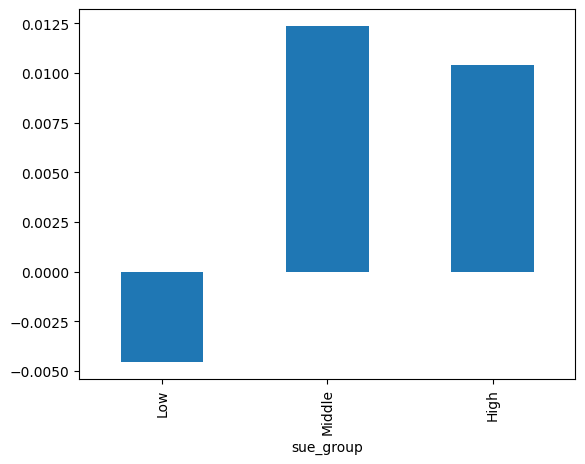

In [12]:
# ===== 2b. The quick (default) chart =====
table["mean"].plot(kind="bar")

**Step 3. The same chart, made for a client.** Six small changes do most of the work:

1. a **clean style** (`plt.rcParams`) for a light background and readable fonts
2. **colors with a meaning**: red = low surprise, grey = middle, blue = high (use the same colors on every slide)
3. **error bars** = the 95% CI
4. the **value and n** written on each bar, so nobody has to read the axis
5. a **title that states the finding** (built from the numbers, so it is always right)
6. no box around the plot (top and right borders off), and a line at 0




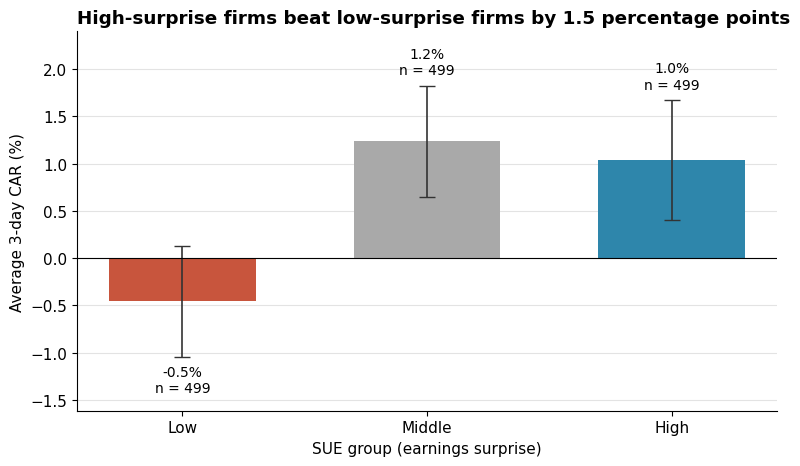

In [13]:
# ===== 2c. Figure 1, made for a client =====

plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E3E3E3",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
#sns.set_theme(style="whitegrid", font_scale=1.1, rc={"axes.grid.axis": "y"})   # 1. theme (once per notebook), horizontal lines only

COLORS = {"Low": "#C8553D", "Middle": "#A9A9A9", "High": "#2E86AB"}    # 2. colors with a meaning

mean = table["mean"] * 100
ci   = table["ci95"] * 100
spread = mean["High"] - mean["Low"]
word = "beat" if spread > 0 else "trail"
title = f"High-surprise firms {word} low-surprise firms by {abs(spread):.1f} percentage points"   # 5. the finding

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(LABELS, mean, yerr=ci, capsize=6, width=0.6,                  # 3. error bars = 95% CI
       color=[COLORS[g] for g in LABELS], error_kw={"elinewidth": 1.2, "ecolor": "#333333"})
for i, g in enumerate(LABELS):                                        # 4. value and n on each bar
    top = mean[g] + ci[g] if mean[g] >= 0 else mean[g] - ci[g]
    ax.annotate(f"{mean[g]:.1f}%\nn = {table.loc[g, 'n']}", (i, top),
                xytext=(0, 6 if mean[g] >= 0 else -6), textcoords="offset points",
                ha="center", va="bottom" if mean[g] >= 0 else "top", fontsize=10)
ax.axhline(0, color="black", linewidth=0.8)                           # 6. line at 0
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("SUE group (earnings surprise)")
ax.set_ylabel("Average 3-day CAR (%)")
ax.margins(y=0.2)
#sns.despine(left=True)                                                # 6. no box
plt.tight_layout()
fig.savefig("part2_groups_my_industry.png", dpi=200)                            # for your slides
plt.show()

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 3. t-test: is High different from Low?</h2>

The **null hypothesis**: High and Low have the same average, and the gap we see is luck.

- **t-statistic** = the gap ÷ its standard error. Beyond about ±2, the gap is large compared with the noise.
- **p-value** = if there were really no difference, how often would we see a gap this large just by luck?
  Below 0.05 we say "unlikely to be luck".

We use Welch's t-test (`equal_var=False`): it does not assume the two groups have the same spread.

In [14]:
# ===== 3. Welch t-test: High vs Low =====
high = events.loc[events["sue_group"] == "High", "car"]
low  = events.loc[events["sue_group"] == "Low",  "car"]

t, p = stats.ttest_ind(high, low, equal_var=False)

gap = (high.mean() - low.mean()) * 100
print(f"High - Low = {gap:.2f} percentage points | t = {t:.2f} | p = {p:.4f}")

# The result in two plain sentences
if gap > 0:
    direction = "more"
else:
    direction = "less"
if p < 0.05:
    verdict = "so we treat it as real (p < 0.05)."
else:
    verdict = "so we cannot rule out luck (p >= 0.05)."
print(f"High-surprise announcements earned on average {abs(gap):.2f} percentage points {direction} than low-surprise announcements.")
print(f"If there were really no difference, a gap this large would appear by luck about {p * 100:.1f}% of the time, {verdict}")

High - Low = 1.49 percentage points | t = 3.39 | p = 0.0007
High-surprise announcements earned on average 1.49 percentage points more than low-surprise announcements.
If there were really no difference, a gap this large would appear by luck about 0.1% of the time, so we treat it as real (p < 0.05).


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 4. Outliers and the regression</h2>

In [15]:
# ===== 4a. Look at the extremes, then winsorize the return at 1% and 99% =====
print(events[["sue", "car"]].describe().round(3))

lo, hi = events["car"].quantile([0.01, 0.99])
events["car_w"] = events["car"].clip(lo, hi)     # clip = pull values outside [lo, hi] to the edge
print(f"\nrows changed by winsorizing: {(events['car'] != events['car_w']).sum()} of {len(events)}")

            sue       car
count  1497.000  1497.000
mean      0.020     0.006
std       0.134     0.069
min      -0.907    -0.252
25%      -0.014    -0.032
50%       0.005     0.004
75%       0.040     0.041
max       0.943     0.426

rows changed by winsorizing: 30 of 1497


In [16]:
# ===== 4b. Regression: original and winsorized =====
model   = smf.ols("car ~ sue", data=events).fit()
model_w = smf.ols("car_w ~ sue", data=events).fit()

print(model.summary())      # full results table, original
print(model_w.summary())    # full results table, winsorized

results = pd.DataFrame({
    "b (slope)":    [model.params["sue"],  model_w.params["sue"]],
    "p-value of b": [model.pvalues["sue"], model_w.pvalues["sue"]],
    "R-squared":    [model.rsquared,           model_w.rsquared],
    "n":            [int(model.nobs),          int(model_w.nobs)],
}, index=["original", "winsorized 1%/99%"]).round(4)
display(results)

# b in plain words (for SUE + 0.01)
b = model_w.params["sue"]
if b > 0:
    move = "higher"
else:
    move = "lower"
print(f"In plain words: when SUE is 0.01 higher, the 3-day CAR is on average {abs(b) * 0.01 * 100:.3f} percentage points {move}.")

                            OLS Regression Results                            
Dep. Variable:                    car   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                     9.940
Date:                Mon, 23 Nov 2026   Prob (F-statistic):            0.00165
Time:                        18:56:49   Log-Likelihood:                 1881.4
No. Observations:                1497   AIC:                            -3759.
Df Residuals:                    1495   BIC:                            -3748.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0052      0.002      2.909      0.0

,b (slope),p-value of b,R-squared,n
original,0.0419,0.0016,0.0066,1497
winsorized 1%/99%,0.0429,0.0007,0.0076,1497


In plain words: when SUE is 0.01 higher, the 3-day CAR is on average 0.043 percentage points higher.


In [17]:
# ===== 4b (continued). Robustness: year effects, loss firms, standard errors clustered by company =====
events["fyearq"] = events["fyearq"].astype(int)           # nullable Int64 -> plain int
events["loss"]   = (events["epspxq"] < 0).astype(int)     # 1 = loss quarter
lo, hi = events["car"].quantile([0.01, 0.99])
events["car_w"] = events["car"].clip(lo, hi)

cl = dict(cov_type="cluster", cov_kwds={"groups": events["gvkey"]})

m1 = smf.ols("car_w ~ sue", data=events).fit(**cl)
m2 = smf.ols("car_w ~ sue + C(fyearq)", data=events).fit(**cl)
m3 = smf.ols("car_w ~ sue * loss + C(fyearq)", data=events).fit(**cl)

summary_col([m1, m2, m3], stars=True,
            model_names=["(1) base", "(2) year FE", "(3) year FE + loss"],
            regressor_order=["sue", "loss", "sue:loss"], drop_omitted=True,
            info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"})

,(1) base,(2) year FE,(3) year FE + loss
sue,0.0429***,0.0439***,0.0332**
,(0.0159),(0.0159),(0.0145)
loss,,,-0.0112**
,,,(0.0046)
sue:loss,,,0.0057
,,,(0.0232)
R-squared,0.0076,0.0217,0.0259
R-squared Adj.,0.0070,0.0177,0.0207
R2,0.008,0.022,0.026
n,1497,1497,1497


**Read b in plain words.** A SUE of 1 means EPS moved by 100% of last quarter's price, which almost never happens. A change of **0.01** (1% of the price) is more natural:

> *When SUE is 0.01 higher, the 3-day CAR is on average b × 0.01 × 100 percentage points higher.*

**R² is small? That is normal.** Returns move for many reasons besides earnings. The surprise can matter on average (a clear slope)
and still explain little of any single company's return. This is a good **limitation** for the report.

**Outliers.** Rules 4 and 5 removed prices below $5 and |SUE| above 1, and winsorizing CAR at 1%/99% changed 30 of 1,497 rows. The original and the winsorized regressions tell the same story (b = 0.0419 vs 0.0429, both p < 0.01), and b stays about the same with year fixed effects and the loss variable (0.043, 0.044, 0.033), so the result does not depend on a few extreme rows.

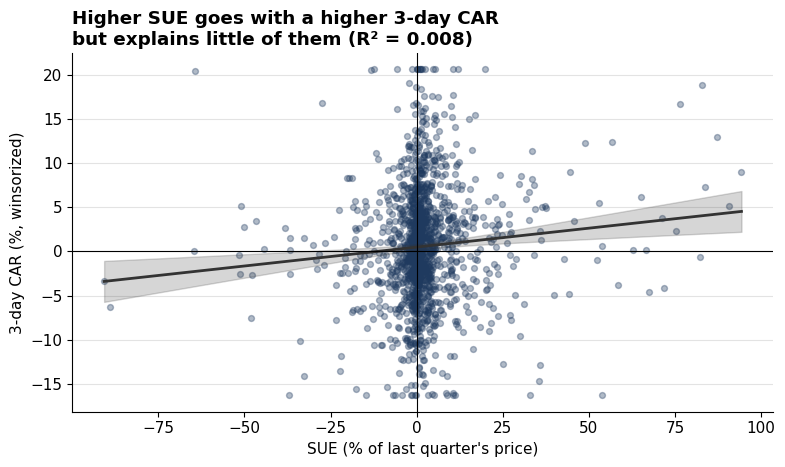

In [18]:
# ===== 4c. Scatter for my industry: every company-quarter and the regression line =====
b  = model_w.params["sue"]
r2 = model_w.rsquared
title = (f"Higher SUE goes with a {'higher' if b > 0 else 'lower'} 3-day CAR\n"
         f"but explains little of them (R² = {r2:.3f})")

# the regression line and its 95% band, from the fitted model
grid = pd.DataFrame({"sue": np.linspace(events["sue"].min(), events["sue"].max(), 100)})
pred = model_w.get_prediction(grid).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(events["sue"] * 100, events["car_w"] * 100,
           s=18, alpha=0.35, color="#1F3A5F")                                   # every company-year
ax.fill_between(grid["sue"] * 100, pred["mean_ci_lower"] * 100, pred["mean_ci_upper"] * 100,
                color="#333333", alpha=0.2)                                     # 95% band
ax.plot(grid["sue"] * 100, pred["mean"] * 100, color="#333333", linewidth=2)  # regression line
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("SUE (% of last quarter's price)")
ax.set_ylabel("3-day CAR (%, winsorized)")
ax.spines[["top", "right"]].set_visible(False)                                  # no box
plt.tight_layout()
fig.savefig("part4_scatter_my_industry.png", dpi=200)
plt.show()

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 5. The peer industry, with a class (OOP)</h2>

Project 3 asks for a **peer comparison**. We need Parts 1 to 4 again for another industry.

**Option 1: copy every cell and change `SIC`.** It works, but you now have two copies of everything.
Fix a bug in one copy and forget the other, and your two industries are no longer built the same way.

**Option 2: write the steps once, as a class, and use it twice.**

| Word | Meaning | Here |
|---|---|---|
| **class** | a recipe | `Industry`: how to build and analyze one industry |
| **object** | one thing made from the recipe | `mine = Industry("13", ...)`, `peer = Industry("63", ...)` |
| **attribute** | data stored inside the object | `self.sic`, `self.name`, `self.events` |
| **method** | a function that belongs to the class | `.build()`, `.ttest()`, `.regression()` |
| `self` | "this object" | inside the recipe, `self.sic` is *this* industry's SIC |
| `__init__` | runs once when the object is created | stores the SIC and the name |

Nothing inside the methods is new: it is the code of Parts 1 to 4, with `SIC` replaced by `self.sic` and `events` by `self.events`.

In [19]:
# ===== 5a. The class =====
class Industry:
    """One industry: build its table, then group, test, and regress."""

    def __init__(self, sic, name):
        self.sic = sic              # attributes: data that belongs to this object
        self.name = name
        self.events = None          # filled by build()
        self.sample_table = None    # filled by build()

    # ---------- Part 1: build the table (the same steps as Part 1) ----------
    def build(self):
        # Step 2. Companies in this industry and their quarterly data
        link = link_all[link_all["sic2"] == self.sic].reset_index(drop=True)
        gv = "'" + "','".join(link["gvkey"].unique()) + "'"
        fa = conn.raw_sql(f"""
            select gvkey, datadate, fyearq, fqtr, epspxq, prccq, rdq
            from comp.fundq
            where gvkey in ({gv})
              and datadate between '{PULL_START}' and '{FY_END}'
              and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
        """, date_cols=["datadate"])
        fa["epspxq"] = fa["epspxq"].astype("float64")
        fa["prccq"] = fa["prccq"].astype("float64")
        r1 = len(fa)
        c1 = fa["gvkey"].nunique()

        # Step 3. Merge 1 (link), valid link on the quarter-end date, one row per company-quarter
        panel = fa.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
        valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
        panel = panel[valid]
        panel = panel.drop_duplicates(["gvkey", "fyearq", "fqtr"])
        panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)
        r2 = len(panel)
        c2 = panel["gvkey"].nunique()

        # Merge 2: EPS four quarters ago and price one quarter ago, matched on a quarter number
        panel["quarter_num"] = panel["fyearq"] * 4 + panel["fqtr"]
        lags = panel[["gvkey", "quarter_num", "epspxq", "prccq"]].dropna(subset=["quarter_num"])
        lag4 = lags[["gvkey", "quarter_num", "epspxq"]].copy()
        lag4["quarter_num"] = lag4["quarter_num"] + 4
        lag4 = lag4.rename(columns={"epspxq": "eps_lag4"})
        lag1 = lags[["gvkey", "quarter_num", "prccq"]].copy()
        lag1["quarter_num"] = lag1["quarter_num"] + 1
        lag1 = lag1.rename(columns={"prccq": "prc_lag1"})
        panel = panel.merge(lag4, on=["gvkey", "quarter_num"], how="left")
        panel = panel.merge(lag1, on=["gvkey", "quarter_num"], how="left")
        r2b = len(panel)
        c2b = panel["gvkey"].nunique()
        panel["sue"] = (panel["epspxq"] - panel["eps_lag4"]) / panel["prc_lag1"]

        # Rules 1 to 5, one at a time
        events = panel[panel["rdq"].notna()].copy()
        r3 = len(events)
        c3 = events["gvkey"].nunique()
        events["rdq"] = pd.to_datetime(events["rdq"]).astype("datetime64[ns]")
        events = events[(events["rdq"] >= FY_START) & (events["rdq"] <= FY_END)].copy()
        r4 = len(events)
        c4 = events["gvkey"].nunique()
        events = events[events["sue"].notna()].copy()
        r5 = len(events)
        c5 = events["gvkey"].nunique()
        events = events[events["prc_lag1"] >= MIN_PRC].copy()
        r6 = len(events)
        c6 = events["gvkey"].nunique()
        events = events[events["sue"].abs() <= MAX_CHG].reset_index(drop=True)
        r7 = len(events)
        c7 = events["gvkey"].nunique()

        # Step 4. Daily stock returns, Merge 3 with the market, abnormal return
        permnos = "'" + "','".join(events["permno"].astype(str).unique()) + "'"
        stock = conn.raw_sql(f"""
            select permno, date, ret
            from crsp.dsf
            where permno in ({permnos})
              and date between '{RET_START}' and '{RET_END}'
        """, date_cols=["date"])
        stock["permno"] = stock["permno"].astype(int)
        stock["ret"] = stock["ret"].astype("float64")
        stock["date"] = stock["date"].astype("datetime64[ns]")
        stock = stock.merge(mkt[["date", "vwretd"]], on="date", how="left")      # mkt from Part 1: the same for every industry
        stock["ar"] = stock["ret"] - stock["vwretd"]

        # Step 5. Day 0 = first trading day on or after rdq; window = trading days n-1, n, n+1
        events["event_id"] = events.index
        rdq_df = events[["event_id", "permno", "rdq"]].sort_values("rdq")
        trading_days = mkt[["date", "t_day"]].rename(columns={"date": "trading_date"})
        day0_map = pd.merge_asof(rdq_df, trading_days, left_on="rdq", right_on="trading_date", direction="forward")
        day0_map = day0_map.dropna(subset=["t_day"])
        window_list = []
        for offset in [-1, 0, 1]:
            w = day0_map[["event_id", "t_day"]].copy()
            w["t_day"] = w["t_day"].astype(int) + offset
            window_list.append(w)
        window_grid = pd.concat(window_list, ignore_index=True)
        window_grid = window_grid.merge(mkt[["t_day", "date"]], on="t_day", how="inner")
        pairs = window_grid.merge(events[["event_id", "permno"]], on="event_id", how="inner")
        pairs = pairs.merge(stock[["permno", "date", "ar"]], on=["permno", "date"], how="inner")
        car_agg = pairs.groupby("event_id")["ar"].agg(car="sum", days_found="count").reset_index()
        events = events.merge(car_agg, on="event_id", how="left")
        events = events[events["days_found"] == 3].reset_index(drop=True)      # Rule 6
        r8 = len(events)
        c8 = events["gvkey"].nunique()

        # The sample construction table for this industry
        self.sample_table = pd.DataFrame({
            "step": ["1. Compustat quarterly data", "2. Merge 1: link", "3. Merge 2: EPS 4 quarters ago, last price",
                     "4. Rule 1: rdq is known", "5. Rule 2: rdq Jan 2021 - Dec 2024", "6. Rule 3: SUE can be computed",
                     "7. Rule 4: last price >= $" + str(MIN_PRC), "8. Rule 5: |SUE| <= " + str(MAX_CHG),
                     "9. Merge 3 + Rule 6: 3 daily abnormal returns"],
            "rows left": [r1, r2, r2b, r3, r4, r5, r6, r7, r8],
            "companies left": [c1, c2, c2b, c3, c4, c5, c6, c7, c8]})

        # Part 2 groups and Part 4 winsorizing, so every method below can use them
        events["sue_group"] = pd.qcut(events["sue"].rank(method="first"), 3, labels=LABELS)
        lo, hi = events["car"].quantile([0.01, 0.99])
        events["car_w"] = events["car"].clip(lo, hi)

        self.events = events
        print(f"{self.name} (SIC {self.sic}): {len(events)} company-quarters, {events['gvkey'].nunique()} companies")
        return self                 # returning self lets us write Industry(...).build() in one line

    # ---------- Part 2: the group table ----------
    def group_table(self):
        t = self.events.groupby("sue_group", observed=True)["car"].agg(n="count", mean="mean", sd="std")
        t["ci95"] = 1.96 * t["sd"] / np.sqrt(t["n"])
        return t

    # ---------- Part 3: the t-test ----------
    def ttest(self):
        high = self.events.loc[self.events["sue_group"] == "High", "car"]
        low  = self.events.loc[self.events["sue_group"] == "Low",  "car"]
        t, p = stats.ttest_ind(high, low, equal_var=False)
        return {"High - Low (pp)": (high.mean() - low.mean()) * 100, "t": t, "p (t-test)": p}

    # ---------- Part 4: the regression (winsorized) ----------
    def regression(self):
        m = smf.ols("car_w ~ sue", data=self.events).fit()
        return {"b": m.params["sue"], "p (b)": m.pvalues["sue"], "R2": m.rsquared}

    # ---------- everything in one row ----------
    def summary(self):
        row = {"industry": self.name, "SIC": self.sic, "n": len(self.events),
               "companies": self.events["gvkey"].nunique()}
        row.update(self.ttest())
        row.update(self.regression())
        return row

In [20]:
# ===== 5b. Two objects from one recipe =====
mine = Industry(SIC, "Oil and Gas Extraction").build()
peer = Industry(PEER_SIC, "Insurance").build()

Oil and Gas Extraction (SIC 13): 1497 company-quarters, 130 companies
Insurance (SIC 63): 1150 company-quarters, 88 companies


In [21]:
# Sample construction table of the peer industry
display(peer.sample_table)

,step,rows left,companies left
0,1. Compustat quarterly data,1959,92
1,2. Merge 1: link,1876,92
2,"3. Merge 2: EPS 4 quarters ago, last price",1876,92
3,4. Rule 1: rdq is known,1846,91
4,5. Rule 2: rdq Jan 2021 - Dec 2024,1280,91
5,6. Rule 3: SUE can be computed,1246,90
6,7. Rule 4: last price >= $5,1157,88
7,8. Rule 5: |SUE| <= 1,1152,88
8,9. Merge 3 + Rule 6: 3 daily abnormal returns,1150,88


In [22]:
# ===== 5c. The comparison table: one row per industry =====
compare = pd.DataFrame([mine.summary(), peer.summary()]).set_index("industry")
compare.round(4)

,SIC,n,companies,High - Low (pp),t,p (t-test),b,p (b),R2
industry,,,,,,,,,
Oil and Gas Extraction,13,1497,130,1.4918,3.3864,0.0007,0.0429,0.0007,0.0076
Insurance,63,1150,88,3.8610,7.3845,0.0000,0.1091,0.0000,0.0244


**Is the difference between the two industries real?** We put both industries in one regression. `peer` = 1 for the peer industry. The coefficient on `sue:peer` is the difference in the slope b between the two industries, and its p-value tests whether that difference could be luck.

In [23]:
# ===== 5c (continued). Test the difference between the two industries =====
my_rows = mine.events[["sue", "car_w"]].copy()
my_rows["peer"] = 0
peer_rows = peer.events[["sue", "car_w"]].copy()
peer_rows["peer"] = 1
both = pd.concat([my_rows, peer_rows], ignore_index=True)

model_diff = smf.ols("car_w ~ sue + peer + sue:peer", data=both).fit()
print(model_diff.summary())

diff = model_diff.params["sue:peer"]
p_diff = model_diff.pvalues["sue:peer"]
print(f"Slope in {peer.name} minus slope in {mine.name} = {diff:.4f} | p = {p_diff:.4f}")

                            OLS Regression Results                            
Dep. Variable:                  car_w   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     14.64
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           1.88e-09
Time:                        18:56:51   Log-Likelihood:                 3479.3
No. Observations:                2647   AIC:                            -6951.
Df Residuals:                    2643   BIC:                            -6927.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0050      0.002      2.940      0.0

**Figure 3. The two industries side by side.** The same chart as Figure 1, with one color per **industry** this time
(keep these colors on every slide). It is a plain function, because it uses two objects at once.

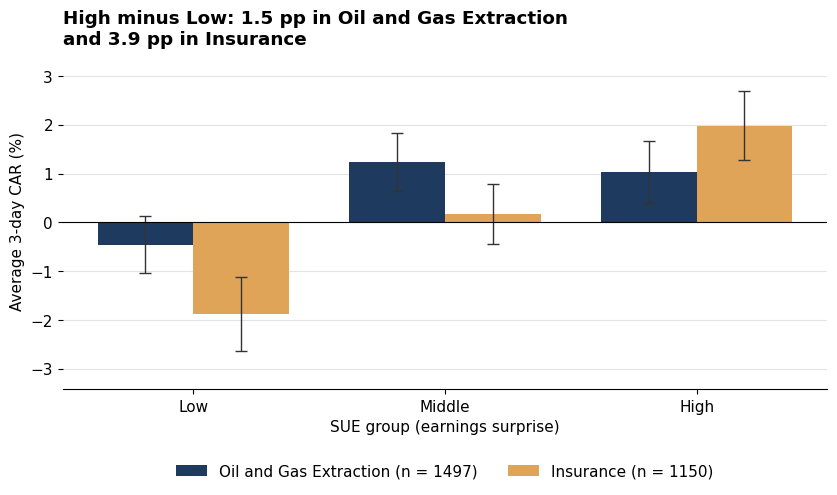

In [24]:
# ===== 5d. Figure 3: my industry vs the peer industry =====
def plot_compare(industries, colors, file_name):
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    x = np.arange(len(LABELS))
    width = 0.38
    for j, ind in enumerate(industries):
        t = ind.group_table()
        ax.bar(x + (j - 0.5) * width, t["mean"] * 100, width, yerr=t["ci95"] * 100, capsize=4,
               color=colors[j], label=f"{ind.name} (n = {len(ind.events)})",
               error_kw={"elinewidth": 1, "ecolor": "#333333"})
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, LABELS)
    gaps = [ind.ttest()["High - Low (pp)"] for ind in industries]
    ax.set_title(f"High minus Low: {gaps[0]:.1f} pp in {industries[0].name}\n"
                 f"and {gaps[1]:.1f} pp in {industries[1].name}", loc="left", fontweight="bold")
    ax.set_xlabel("SUE group (earnings surprise)")
    ax.set_ylabel("Average 3-day CAR (%)")
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))   # legend under the chart
    ax.margins(y=0.15)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    fig.savefig(file_name, dpi=200)
    plt.show()

plot_compare([mine, peer], colors=["#1F3A5F", "#E0A458"], file_name="part5_groups_both_industries.png")

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Part 7. Project 3 figures, plain words for both industries, and the optional parts</h2>

**Plain words for both industries.** The comparison table above has the numbers. Here I write the t-test and the regression in plain sentences for each industry, so I can use them on slide 5.

In [25]:
# loop over my industry and the peer industry and write the results in plain words
for ind in [mine, peer]:
    tt = ind.ttest()
    rr = ind.regression()

    # t-test: High minus Low
    gap = tt["High - Low (pp)"]
    if gap > 0:
        direction = "more"
    else:
        direction = "less"
    if tt["p (t-test)"] < 0.05:
        verdict = "so we treat it as real (p < 0.05)."
    else:
        verdict = "so we cannot rule out luck (p >= 0.05)."

    # regression: b for SUE + 0.01
    b_ind = rr["b"]
    if b_ind > 0:
        move = "higher"
    else:
        move = "lower"

    print(ind.name)
    print(f"  t-test: high-surprise announcements earned {abs(gap):.2f} percentage points {direction} than low-surprise ones (t = {tt['t']:.2f}, p = {tt['p (t-test)']:.4f}), {verdict}")
    print(f"  regression: when SUE is 0.01 higher, the 3-day CAR is on average {abs(b_ind) * 0.01 * 100:.3f} percentage points {move} (b = {b_ind:.4f}, p = {rr['p (b)']:.4f}, R2 = {rr['R2']:.4f}, n = {len(ind.events)})")
    print()

Oil and Gas Extraction
  t-test: high-surprise announcements earned 1.49 percentage points more than low-surprise ones (t = 3.39, p = 0.0007), so we treat it as real (p < 0.05).
  regression: when SUE is 0.01 higher, the 3-day CAR is on average 0.043 percentage points higher (b = 0.0429, p = 0.0007, R2 = 0.0076, n = 1497)

Insurance
  t-test: high-surprise announcements earned 3.86 percentage points more than low-surprise ones (t = 7.38, p = 0.0000), so we treat it as real (p < 0.05).
  regression: when SUE is 0.01 higher, the 3-day CAR is on average 0.109 percentage points higher (b = 0.1091, p = 0.0000, R2 = 0.0244, n = 1150)



**Optional: the robustness models for the peer industry.** The same three models as in Part 4, now for the peer industry, so I can check if b stays about the same there too.

In [26]:
# copy the peer table so I do not change the original
pe = peer.events.copy()
pe["fyearq"] = pe["fyearq"].astype(int)          # year as a plain number
pe["loss"] = (pe["epspxq"] < 0).astype(int)      # 1 = loss quarter

# standard errors clustered by company, the same as for my industry
cl_peer = dict(cov_type="cluster", cov_kwds={"groups": pe["gvkey"]})

# (1) base, (2) with year fixed effects, (3) with year fixed effects and loss
p1 = smf.ols("car_w ~ sue", data=pe).fit(**cl_peer)
p2 = smf.ols("car_w ~ sue + C(fyearq)", data=pe).fit(**cl_peer)
p3 = smf.ols("car_w ~ sue * loss + C(fyearq)", data=pe).fit(**cl_peer)

summary_col([p1, p2, p3], stars=True,
            model_names=["(1) base", "(2) year FE", "(3) year FE + loss"],
            regressor_order=["sue", "loss", "sue:loss"], drop_omitted=True,
            info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"})

,(1) base,(2) year FE,(3) year FE + loss
sue,0.1091***,0.1099***,0.1093***
,(0.0285),(0.0289),(0.0314)
loss,,,-0.0152*
,,,(0.0089)
sue:loss,,,-0.0256
,,,(0.0573)
R-squared,0.0244,0.0248,0.0328
R-squared Adj.,0.0236,0.0205,0.0269
R2,0.024,0.025,0.033
n,1150,1150,1150


**Project 3 Figure 1.** Average 3-day CAR for the Low, Middle and High SUE groups, both industries side by side, with the 95% CI and the number of announcements on every bar. One color per industry, and I use the same two colors on every slide.

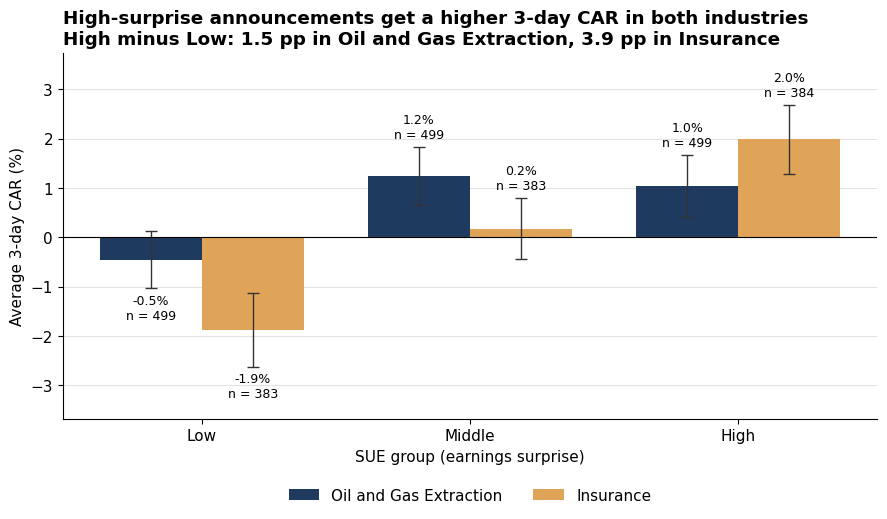

In [27]:
# one color for each industry (the same on every slide)
IND_COLORS = {mine.name: "#1F3A5F", peer.name: "#E0A458"}

fig, ax = plt.subplots(figsize=(9, 5.4))
x = np.arange(len(LABELS))
width = 0.38

for j, ind in enumerate([mine, peer]):
    t = ind.group_table()
    xpos = x + (j - 0.5) * width          # left bar for my industry, right bar for the peer

    # bars with the 95% CI as error bars
    ax.bar(xpos, t["mean"] * 100, width, yerr=t["ci95"] * 100, capsize=4,
           color=IND_COLORS[ind.name], label=ind.name,
           error_kw={"elinewidth": 1, "ecolor": "#333333"})

    # write the average and the number of announcements on each bar
    for i, g in enumerate(LABELS):
        m = t.loc[g, "mean"] * 100
        c = t.loc[g, "ci95"] * 100
        if m >= 0:
            ypos = m + c
            shift = 4
            va = "bottom"
        else:
            ypos = m - c
            shift = -4
            va = "top"
        ax.annotate(f"{m:.1f}%\nn = {t.loc[g, 'n']}", (xpos[i], ypos), xytext=(0, shift),
                    textcoords="offset points", ha="center", va=va, fontsize=9)

# title from the numbers, so it always matches the results
gap_mine = mine.ttest()["High - Low (pp)"]
gap_peer = peer.ttest()["High - Low (pp)"]
if gap_mine > 0 and gap_peer > 0:
    title = (f"High-surprise announcements get a higher 3-day CAR in both industries\n"
             f"High minus Low: {gap_mine:.1f} pp in {mine.name}, {gap_peer:.1f} pp in {peer.name}")
else:
    title = f"High minus Low: {gap_mine:.1f} pp in {mine.name}, {gap_peer:.1f} pp in {peer.name}"

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, LABELS)
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("SUE group (earnings surprise)")
ax.set_ylabel("Average 3-day CAR (%)")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.margins(y=0.2)
plt.tight_layout()
fig.savefig("figure1_groups_both_industries.png", dpi=200)
plt.show()

**Project 3 Figure 2.** Every announcement as a dot (SUE on the x-axis, CAR on the y-axis), one color per industry, and each industry's regression line.

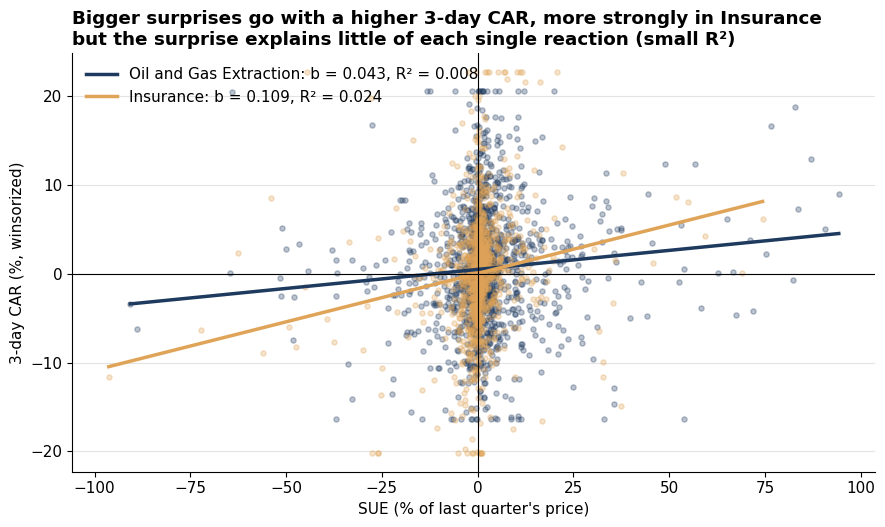

In [28]:
fig, ax = plt.subplots(figsize=(9, 5.4))
slopes = {}

for ind in [mine, peer]:
    # the regression for this industry (winsorized CAR, the same as Part 4)
    m = smf.ols("car_w ~ sue", data=ind.events).fit()
    slopes[ind.name] = m.params["sue"]

    # dots: every announcement
    ax.scatter(ind.events["sue"] * 100, ind.events["car_w"] * 100,
               s=14, alpha=0.3, color=IND_COLORS[ind.name])

    # line: from the smallest to the largest SUE of this industry
    line = pd.DataFrame({"sue": np.linspace(ind.events["sue"].min(), ind.events["sue"].max(), 100)})
    line["pred"] = m.predict(line)
    ax.plot(line["sue"] * 100, line["pred"] * 100, color=IND_COLORS[ind.name], linewidth=2.5,
            label=f"{ind.name}: b = {m.params['sue']:.3f}, R² = {m.rsquared:.3f}")

# which industry has the steeper line?
if slopes[peer.name] > slopes[mine.name]:
    steeper = peer.name
else:
    steeper = mine.name
title = (f"Bigger surprises go with a higher 3-day CAR, more strongly in {steeper}\n"
         f"but the surprise explains little of each single reaction (small R²)")

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(title, loc="left", fontweight="bold")
ax.set_xlabel("SUE (% of last quarter's price)")
ax.set_ylabel("3-day CAR (%, winsorized)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("figure2_scatter_both_industries.png", dpi=200)
plt.show()

Oil and Gas Extraction: 307 loss quarters out of 1497 (20.5%)
Insurance: 230 loss quarters out of 1150 (20.0%)


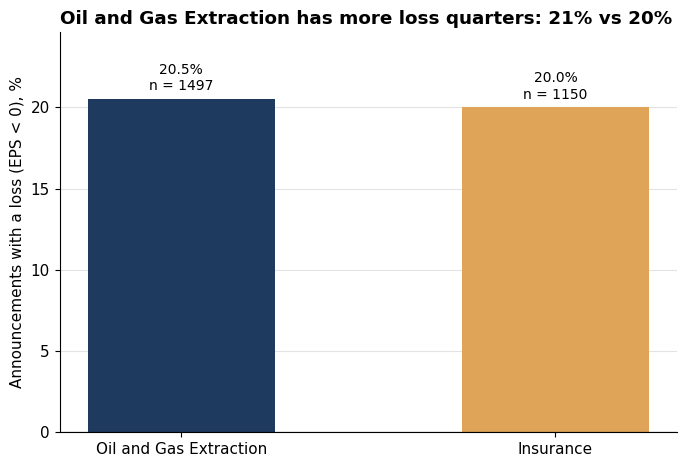

Oil and Gas Extraction: b all quarters = 0.0429 | b profit quarters only = 0.0404 (p = 0.0082, n = 1190)
Insurance: b all quarters = 0.1091 | b profit quarters only = 0.1074 (p = 0.0001, n = 920)

Difference in b: 0.0662 with all quarters, 0.0670 with profit quarters only
The guess is not supported by the data: the loss share does not explain the difference.


In [29]:
# Check 1: share of loss quarters (EPS < 0) in each industry
loss_share = {}
for ind in [mine, peer]:
    is_loss = ind.events["epspxq"] < 0
    loss_share[ind.name] = is_loss.mean() * 100
    print(f"{ind.name}: {is_loss.sum()} loss quarters out of {len(ind.events)} ({loss_share[ind.name]:.1f}%)")

# title from the numbers
if loss_share[mine.name] > loss_share[peer.name]:
    title = f"{mine.name} has more loss quarters: {loss_share[mine.name]:.0f}% vs {loss_share[peer.name]:.0f}%"
else:
    title = f"{mine.name} does not have more loss quarters: {loss_share[mine.name]:.0f}% vs {loss_share[peer.name]:.0f}%"

fig, ax = plt.subplots(figsize=(7, 4.8))
names = [mine.name, peer.name]
values = [loss_share[mine.name], loss_share[peer.name]]
ax.bar(names, values, width=0.5, color=[IND_COLORS[mine.name], IND_COLORS[peer.name]])

# write the % and n on each bar
for i, ind in enumerate([mine, peer]):
    ax.annotate(f"{values[i]:.1f}%\nn = {len(ind.events)}", (i, values[i]), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=10)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(title, loc="left", fontweight="bold")
ax.set_ylabel("Announcements with a loss (EPS < 0), %")
ax.margins(y=0.2)
plt.tight_layout()
fig.savefig("figure3_loss_share.png", dpi=200)
plt.show()

# Check 2: the slope b with all quarters and with only profit quarters (EPS >= 0)
b_all = {}
b_profit = {}
for ind in [mine, peer]:
    m_all = smf.ols("car_w ~ sue", data=ind.events).fit()
    profit = ind.events[ind.events["epspxq"] >= 0]
    m_profit = smf.ols("car_w ~ sue", data=profit).fit()
    b_all[ind.name] = m_all.params["sue"]
    b_profit[ind.name] = m_profit.params["sue"]
    print(f"{ind.name}: b all quarters = {m_all.params['sue']:.4f} | b profit quarters only = {m_profit.params['sue']:.4f} (p = {m_profit.pvalues['sue']:.4f}, n = {int(m_profit.nobs)})")

# do the two slopes get closer without the loss quarters?
diff_all = abs(b_all[peer.name] - b_all[mine.name])
diff_profit = abs(b_profit[peer.name] - b_profit[mine.name])
print(f"\nDifference in b: {diff_all:.4f} with all quarters, {diff_profit:.4f} with profit quarters only")
if loss_share[mine.name] > loss_share[peer.name] and diff_profit < diff_all:
    print("The guess is supported: Oil and Gas has more loss quarters, and the slopes get closer without them.")
else:
    print("The guess is not supported by the data: the loss share does not explain the difference.")

**Optional: CAR from day −5 to day +5 for each SUE group (my industry).** I use the daily abnormal returns and the Day 0 dates from Part 1, take 11 trading days around each announcement, average them for each SUE group, and add them up day by day.

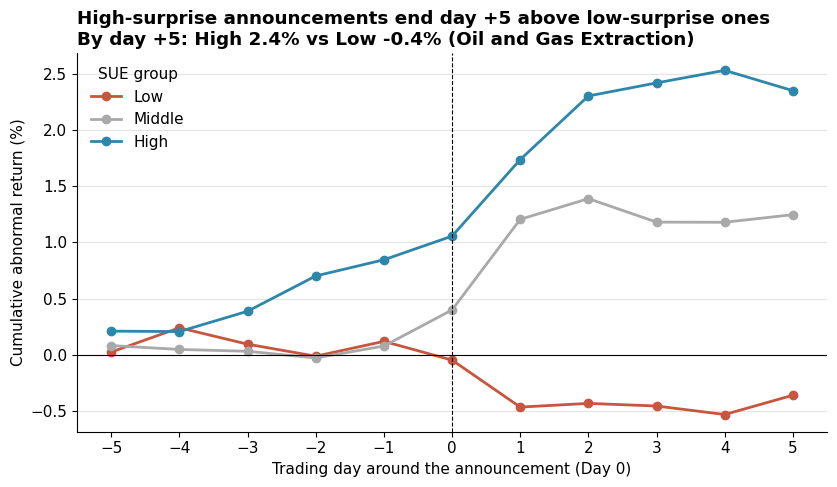

In [30]:
# Day 0 trading day of every announcement in my final sample, with its SUE group
day0 = day0_map[["event_id", "t_day"]].dropna()
day0 = day0.merge(events[["event_id", "permno", "sue_group"]], on="event_id", how="inner")

# make 11 rows for each announcement, one for each day from -5 to +5
window_list = []
for offset in range(-5, 6):
    w = day0.copy()
    w["window_day"] = offset
    w["t_day"] = w["t_day"].astype(int) + offset
    window_list.append(w)
window11 = pd.concat(window_list, ignore_index=True)

# trading day number -> date, then add the abnormal return of that stock on that date
window11 = window11.merge(mkt[["t_day", "date"]], on="t_day", how="inner")
window11 = window11.merge(stock[["permno", "date", "ar"]], on=["permno", "date"], how="inner")

# average abnormal return for each SUE group and each day
daily_avg = window11.groupby(["sue_group", "window_day"], observed=True)["ar"].mean().reset_index()

# add the days up from day -5 to get the cumulative abnormal return
daily_avg = daily_avg.sort_values(["sue_group", "window_day"])
daily_avg["cum_car"] = daily_avg.groupby("sue_group", observed=True)["ar"].cumsum() * 100

# the value on day +5 for the title
end_high = daily_avg[(daily_avg["sue_group"] == "High") & (daily_avg["window_day"] == 5)]["cum_car"].iloc[0]
end_low = daily_avg[(daily_avg["sue_group"] == "Low") & (daily_avg["window_day"] == 5)]["cum_car"].iloc[0]

fig, ax = plt.subplots(figsize=(8.5, 5))
for g in LABELS:
    one = daily_avg[daily_avg["sue_group"] == g]
    ax.plot(one["window_day"], one["cum_car"], marker="o", linewidth=2, color=COLORS[g], label=g)

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")     # Day 0 = announcement day
ax.set_xticks(range(-5, 6))
if end_high > end_low:
    first_line = "High-surprise announcements end day +5 above low-surprise ones"
else:
    first_line = "High-surprise announcements do not end day +5 above low-surprise ones"
ax.set_title(f"{first_line}\n"
             f"By day +5: High {end_high:.1f}% vs Low {end_low:.1f}% ({mine.name})", loc="left", fontweight="bold")
ax.set_xlabel("Trading day around the announcement (Day 0)")
ax.set_ylabel("Cumulative abnormal return (%)")
ax.legend(title="SUE group", frameon=False)
plt.tight_layout()
fig.savefig("figure_optional_car_days.png", dpi=200)
plt.show()

<h2 style="background:#7b1e1e; color:white; padding:8px 14px; border-radius:4px">Part 6. Project 3 checklist</h2>

**Analysis**

- [ ] Your Project 2 table, revised with my comments (rules 1 to 6, the sample construction table).
- [ ] Outliers: say what you did (the rules, and winsorizing CAR at 1%/99% or not) and show that the result does not depend on it.
- [ ] **Figure 1**: average CAR by SUE group with 95% CI.
- [ ] **t-test** High vs Low, in two plain sentences.
- [ ] **Regression** CAR = a + b × SUE: b in plain words (for SUE + 0.01), its p-value, R², and n.
- [ ] **Peer industry**: the same steps, one comparison table, and Figure 3.

**Figures (every figure)**

- [ ] The title states the **finding**, not the topic.
- [ ] Axis labels with **units** (%).
- [ ] The **same color for the same thing** on every slide.
- [ ] A line at 0.

**Interpretation**

- Results do **not** need to be significant. Explain what you find and what it means for the client.
- Name at least one **limitation** (small R², few companies, one period, CAR measures only 3 days).

**Before you submit:** Kernel > Restart & Run All, and check that every number in the report matches the notebook.

**Limitations**

- The 3-day CAR measures only a short reaction; it does not show later drift.
- The R² is small: earnings surprise explains little of any single announcement's return.
- One period (2021 to 2024) and a limited number of companies, so the result may not hold in other years.
- EPS and prices are not adjusted for stock splits (for example, a reverse split), and some extreme SUE values come from reorganization quarters.

In [31]:
conn.close()